In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from pydicom.data import get_testdata_file

# Fichier de test fourni avec pydicom (scanner CT anonymisé)
chemin = get_testdata_file("CT_small.dcm")
ds = pydicom.dcmread(chemin)          # ds = "dataset" : en-tête + pixels

champs = [
    ("Modality", "Type d'examen"),
    ("Manufacturer", "Fabricant de l'appareil"),
    ("Rows", "Hauteur (pixels)"),
    ("Columns", "Largeur (pixels)"),
    ("PixelSpacing", "Taille d'un pixel (mm)"),
    ("SliceThickness", "Épaisseur de coupe (mm)"),
    ("BitsAllocated", "Bits par pixel"),
    ("RescaleSlope", "Rescale Slope"),
    ("RescaleIntercept", "Rescale Intercept"),
    ("WindowCenter", "Centre de fenêtre conseillé"),
    ("WindowWidth", "Largeur de fenêtre conseillée"),
]

for tag, description in champs:
    print(f"{description:32} : {getattr(ds, tag, 'absent')}")

Type d'examen                    : CT
Fabricant de l'appareil          : GE MEDICAL SYSTEMS
Hauteur (pixels)                 : 128
Largeur (pixels)                 : 128
Taille d'un pixel (mm)           : [0.661468, 0.661468]
Épaisseur de coupe (mm)          : 5.000000
Bits par pixel                   : 16
Rescale Slope                    : 1
Rescale Intercept                : -1024
Centre de fenêtre conseillé      : absent
Largeur de fenêtre conseillée    : absent


Brut  -> type : int16 | forme : (128, 128) | min : 128 | max : 2191
HU    -> min : -896.0 | max : 1167.0
Taille réelle : 84.7 mm x 84.7 mm


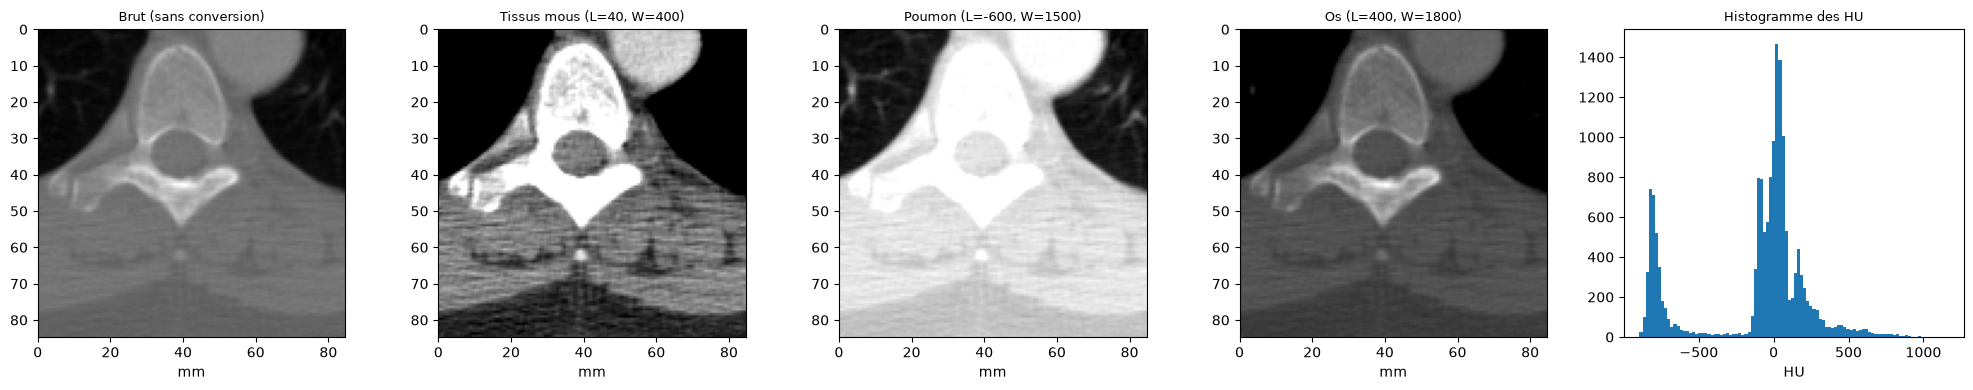

In [2]:
# 1. Les pixels bruts
brut = ds.pixel_array
print("Brut  -> type :", brut.dtype, "| forme :", brut.shape, "| min :", brut.min(), "| max :", brut.max())

# 2. Conversion en unités Hounsfield
hu = brut.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
print("HU    -> min :", hu.min(), "| max :", hu.max())

# 3. Taille réelle, pour afficher des axes en mm
dy, dx = (float(v) for v in ds.PixelSpacing)
hauteur_mm, largeur_mm = ds.Rows * dy, ds.Columns * dx
print(f"Taille réelle : {largeur_mm:.1f} mm x {hauteur_mm:.1f} mm")

# 4. Même fonction de fenêtrage qu'en S1
def fenetrage(img, centre, largeur):
    bas, haut = centre - largeur / 2, centre + largeur / 2
    img = np.clip(img, bas, haut)
    return ((img - bas) / (haut - bas) * 255).astype(np.uint8)

vues = {
    "Brut (sans conversion)": brut,
    "Tissus mous (L=40, W=400)": fenetrage(hu, 40, 400),
    "Poumon (L=-600, W=1500)": fenetrage(hu, -600, 1500),
    "Os (L=400, W=1800)": fenetrage(hu, 400, 1800),
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (titre, im) in zip(axes, vues.items()):
    ax.imshow(im, cmap="gray", extent=[0, largeur_mm, hauteur_mm, 0])   # axes en mm
    ax.set_title(titre, fontsize=9); ax.set_xlabel("mm")

# 5. Histogramme : la répartition des valeurs en HU
axes[4].hist(hu.ravel(), bins=100)
axes[4].set_title("Histogramme des HU", fontsize=9); axes[4].set_xlabel("HU")
plt.tight_layout(); plt.show()